# Análisis de la generación: filtro de preguntas y resultados por combinación

Genera, a partir de los archivos de evaluación ya existentes, las cifras de generación que cita el documento del trabajo de grado.

| Sección | Qué produce | Dónde se usa en el documento |
|---|---|---|
| 1 | Filtro de preguntas con recuperación exitosa en ambos pipelines (196 de 296) | Sección 8.9 |
| 2 | Métricas de las 8 combinaciones y comprobación contra el resumen guardado | Tabla 13 |
| 3 | Promedio por modelo, por prompt y por pipeline | Tabla 14 |
| 4 | Gráfico del promedio compuesto por combinación | Apoyo a la sección 9.5 |

Las pruebas de Wilcoxon de esta etapa (Tablas 15 y 16) están en `pruebas_estadisticas.ipynb`. Ejecutar desde la carpeta del proyecto. Salidas en `validacion/reporte_generacion/`.

El **promedio compuesto** es la media de las cuatro métricas (`faithfulness`, `answer_relevancy`, `answer_correctness`, `semantic_similarity`). En las Tablas 13 y 14 se calcula sobre las medias por combinación; en las pruebas de Wilcoxon (otro notebook) se calcula por respuesta. Difieren solo en el cuarto decimal, porque una respuesta tiene una métrica vacía.

In [1]:
%pip install -q pandas numpy openpyxl matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

DIR_VALIDACION = Path("./validacion")
DIR_CK = DIR_VALIDACION / "checkpoints_evaluacion"
RUTA_DETALLE = DIR_VALIDACION / "evaluacion_generacion_detalle.csv"
RUTA_RESUMEN = DIR_VALIDACION / "evaluacion_generacion_resumen.csv"
DIR_SALIDA = DIR_VALIDACION / "reporte_generacion"
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

PREC, REC = "llm_context_precision_with_reference", "context_recall"
METRICAS = ["faithfulness", "answer_relevancy", "answer_correctness", "semantic_similarity"]
ETIQ_PIPE = {"openai_cs800": "OpenAI denso", "bge_m3_hibrido_cs800": "BGE-m3 híbrido"}
ETIQ_LLM = {"claude-sonnet-5": "Sonnet 5", "claude-haiku-4.5": "Haiku 4.5"}

## 1. Filtro: preguntas con recuperación exitosa en ambos pipelines (sección 8.9)

Se conservan las preguntas en las que **ambos** pipelines tuvieron precisión y recall de contexto mayores que cero. Se comprueba además que el conjunto resultante coincide con las preguntas que se usaron de verdad en la generación.

In [3]:
def cargar(archivo):
    return pd.read_csv(DIR_CK / archivo, usecols=["user_input", PREC, REC]).set_index("user_input")

openai = cargar("openai/text-embedding-3-large_cs800.csv")
bge = cargar("BAAI/bge-m3_cs800_hibrido.csv")

ok_openai = (openai[PREC] > 0) & (openai[REC] > 0)
ok_bge = (bge[PREC] > 0) & (bge[REC] > 0)
ok_ambos = ok_openai & ok_bge.reindex(openai.index)

det = pd.read_csv(RUTA_DETALLE, usecols=["user_input", "pipeline_retrieve", "modelo_llm", "estilo_prompt"] + METRICAS)
usadas = set(det["user_input"])

filtro = pd.DataFrame({
    "Concepto": ["Preguntas del dataset", "Exitosas en OpenAI denso", "Exitosas en BGE-m3 híbrido",
                 "Exitosas en ambos (filtro)", "Preguntas usadas en la generación", "El filtro coincide con las usadas"],
    "Valor": [len(openai), int(ok_openai.sum()), int(ok_bge.sum()), int(ok_ambos.sum()), len(usadas),
              set(ok_ambos[ok_ambos].index) == usadas],
})
display(filtro)
print(f"Proporción conservada: {100 * ok_ambos.mean():.1f} %")

,Concepto,Valor
0,Preguntas del dataset,296
1,Exitosas en OpenAI denso,245
2,Exitosas en BGE-m3 híbrido,219
3,Exitosas en ambos (filtro),196
4,Preguntas usadas en la generación,196
5,El filtro coincide con las usadas,True


Proporción conservada: 66.2 %


## 2. Las 8 combinaciones (Tabla 13)

Se recalculan los promedios desde el detalle por respuesta y se comparan con el archivo de resumen que se guardó al evaluar, como control.

In [4]:
det["promedio"] = det[METRICAS].mean(axis=1)
tabla13 = (det.groupby(["pipeline_retrieve", "modelo_llm", "estilo_prompt"])[METRICAS + ["promedio"]].mean()
              .reset_index().sort_values("promedio", ascending=False).reset_index(drop=True))
# En la Tabla 13 el promedio es la media de las cuatro métricas ya promediadas por combinación
# (así aparece en el resumen guardado). Las pruebas de Wilcoxon usan, en cambio, el promedio
# de cada respuesta, porque necesitan un valor por pregunta.
tabla13["promedio"] = tabla13[METRICAS].mean(axis=1)
tabla13 = tabla13.sort_values("promedio", ascending=False).reset_index(drop=True)
tabla13["Retrieve"] = tabla13["pipeline_retrieve"].map(ETIQ_PIPE)
tabla13["Modelo"] = tabla13["modelo_llm"].map(ETIQ_LLM)
tabla13["Prompt"] = tabla13["estilo_prompt"].str.capitalize()
tabla13 = tabla13[["Retrieve", "Modelo", "Prompt"] + METRICAS + ["promedio"]]
display(tabla13.round(4))

# Control contra el resumen guardado
res = pd.read_csv(RUTA_RESUMEN)
res["clave"] = res["pipeline_retrieve"] + "|" + res["modelo_llm"] + "|" + res["estilo_prompt"]
calc = det.groupby(["pipeline_retrieve", "modelo_llm", "estilo_prompt"])[METRICAS].mean()
calc.index = [ "|".join(i) for i in calc.index ]
dif = (res.set_index("clave")[METRICAS] - calc.reindex(res["clave"])).abs().max().max()
print(f"Diferencia máxima con evaluacion_generacion_resumen.csv: {dif:.2e}")

,Retrieve,Modelo,Prompt,faithfulness,answer_relevancy,answer_correctness,semantic_similarity,promedio
0,OpenAI denso,Haiku 4.5,Estructurado,0.9593,0.7732,0.6691,0.7990,0.8002
1,BGE-m3 híbrido,Haiku 4.5,Estructurado,0.9643,0.7598,0.6440,0.7909,0.7897
2,OpenAI denso,Sonnet 5,Directo,0.9547,0.7209,0.6805,0.8005,0.7891
3,BGE-m3 híbrido,Sonnet 5,Estructurado,0.9415,0.7221,0.6881,0.8016,0.7883
4,OpenAI denso,Sonnet 5,Estructurado,0.9408,0.7007,0.7030,0.8028,0.7868
5,OpenAI denso,Haiku 4.5,Directo,0.9478,0.7646,0.6466,0.7812,0.7850
6,BGE-m3 híbrido,Sonnet 5,Directo,0.9679,0.7233,0.6476,0.7985,0.7843
7,BGE-m3 híbrido,Haiku 4.5,Directo,0.9557,0.7556,0.6293,0.7747,0.7788


Diferencia máxima con evaluacion_generacion_resumen.csv: 1.11e-16


## 3. Efecto de cada variable (Tabla 14)

In [5]:
# Cada nivel se promedia sobre las combinaciones de la Tabla 13 que lo contienen (4 por nivel),
# de modo que la Tabla 14 es consistente con la Tabla 13.
def promedios(columna):
    return tabla13.groupby(columna)[METRICAS + ["promedio"]].mean()

t_modelo = promedios("Modelo")
t_prompt = promedios("Prompt")
t_pipe = promedios("Retrieve")
tabla14 = pd.concat({"Modelo": t_modelo, "Prompt": t_prompt, "Retrieve": t_pipe}, names=["Variable", "Nivel"])
display(tabla14.round(4))
print("Diferencia de promedio compuesto entre modelos (Haiku − Sonnet): "
      f"{t_modelo.loc['Haiku 4.5', 'promedio'] - t_modelo.loc['Sonnet 5', 'promedio']:+.4f}")

faithfulness  answer_relevancy  answer_correctness  \
Variable Nivel                                                                
Modelo   Haiku 4.5             0.9568            0.7633              0.6472   
         Sonnet 5              0.9512            0.7167              0.6798   
Prompt   Directo               0.9565            0.7411              0.6510   
         Estructurado          0.9515            0.7390              0.6760   
Retrieve BGE-m3 híbrido        0.9574            0.7402              0.6522   
         OpenAI denso          0.9506            0.7398              0.6748   

                         semantic_similarity  promedio  
Variable Nivel                                          
Modelo   Haiku 4.5                    0.7864    0.7884  
         Sonnet 5                     0.8008    0.7871  
Prompt   Directo                      0.7887    0.7843  
         Estructurado                 0.7986    0.7913  
Retrieve BGE-m3 híbrido               0.7914    0.7853  
         OpenAI denso                 0.7959    0.7903

Diferencia de promedio compuesto entre modelos (Haiku − Sonnet): +0.0013


## 4. Gráfico del promedio compuesto por combinación

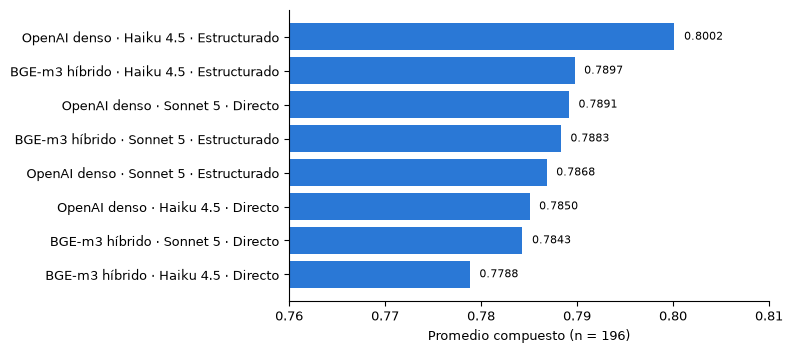

In [6]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
et = (tabla13["Retrieve"] + " · " + tabla13["Modelo"] + " · " + tabla13["Prompt"]).iloc[::-1]
vals = tabla13["promedio"].iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(et, vals, color="#2a78d6")
for y, v in enumerate(vals):
    ax.text(v + 0.001, y, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlim(0.76, 0.81)
ax.set_xlabel("Promedio compuesto (n = 196)")
fig.tight_layout()
fig.savefig(DIR_SALIDA / "promedio_compuesto_por_combinacion.png", dpi=200)
plt.show()

## 5. Exportar

In [7]:
with pd.ExcelWriter(DIR_SALIDA / "reporte_generacion.xlsx") as xw:
    filtro.to_excel(xw, sheet_name="Filtro_196", index=False)
    tabla13.to_excel(xw, sheet_name="Tabla13_combinaciones", index=False)
    tabla14.to_excel(xw, sheet_name="Tabla14_efectos")
filtro.to_csv(DIR_SALIDA / "filtro_preguntas.csv", index=False, encoding="utf-8-sig")
tabla13.to_csv(DIR_SALIDA / "tabla13_combinaciones.csv", index=False, encoding="utf-8-sig")
tabla14.to_csv(DIR_SALIDA / "tabla14_efectos.csv", encoding="utf-8-sig")
print("Guardado en", DIR_SALIDA.resolve())

Guardado en C:\Users\gomex\OneDrive\Escritorio\TG - Pruebas 2\validacion\reporte_generacion
